# Solutions to notebook 8: Eigenvalue problems and pseudospectra

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/08_eigenvalue_problems.ipynb)

Worked solutions to the exercises at the end of [notebook 8](../notebooks/08_eigenvalue_problems.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct                 # discrete cosine transform, used only inside clenshaw_curtis (notebooks 7 and 10)
from scipy.linalg import eig, expm
from scipy.optimize import brentq

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))
    D -= np.diag(D.sum(axis=1))
    return D, x

# fourier_diff2_matrix(N) from notebook 2, used for an independent check in exercise 2
def fourier_diff2_matrix(N):
    """Second-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]
    D2 = np.full((N, N), -np.pi**2 / (3 * h**2) - 1 / 6)
    off = k != 0
    D2[off] = -0.5 * (-1.0) ** k[off] / np.sin(k[off] * h / 2) ** 2
    return D2

# clenshaw_curtis(N), as pasted in notebook 6: weights w_j with ∫ f dx ≈ Σ w_j f(x_j) on the Chebyshev points; derived in notebook 10
def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)
    w = dct(moments, type=1) / N
    w[0] /= 2
    w[N] /= 2
    return x, w

# functions from notebook 8
def dirichlet_d2(N):
    """Second-derivative matrix acting on the interior values, for u(±1) = 0, and the interior points."""
    D, x = cheb(N)
    return (D @ D)[1:-1, 1:-1], x[1:-1]

def convection_diffusion(N, nu):
    """Matrix of ν u'' + u' with u(±1) = 0, acting on the interior values, and the interior points."""
    D, x = cheb(N)
    return (nu * D @ D + D)[1:-1, 1:-1], x[1:-1]

def exact_cd_eigenvalues(nu, count):
    return -1 / (4 * nu) - nu * (np.arange(1, count + 1) * np.pi / 2) ** 2

def weighted(matrix, N):
    """W^(1/2) A W^(-1/2): the matrix as it acts on vectors measured in the discrete L2 norm."""
    s = np.sqrt(clenshaw_curtis(N)[1][1:-1])
    return s[:, None] * matrix / s[None, :]

## Exercise 1

For the model problem of 8.1, count the leading eigenvalues with relative error below
$10^{-6}$ for $N = 24, 48, 96$ and $192$. Express each count as a fraction of $N$. Does the
fraction approach $2/\pi$?

Repeat the computation of 8.1 for each $N$: sort the eigenvalues of the interior matrix from the
smallest $|\lambda|$ upwards, compare with $-(k\pi/2)^2$, and count how many leading ones are
within the tolerance. The rule of $\pi$ points per wavelength says that no more than about
$2N/\pi$ can be right, so the fraction should not exceed $2/\pi = 0.637$. The question is how
close it gets.

   N   accurate to 1e-6   fraction of N    2N/π    2N/π − count
  24            9            0.375       15.3         6.3
  48           24            0.500       30.6         6.6
  96           52            0.542       61.1         9.1
 192          112            0.583      122.2        10.2
2/π = 0.637


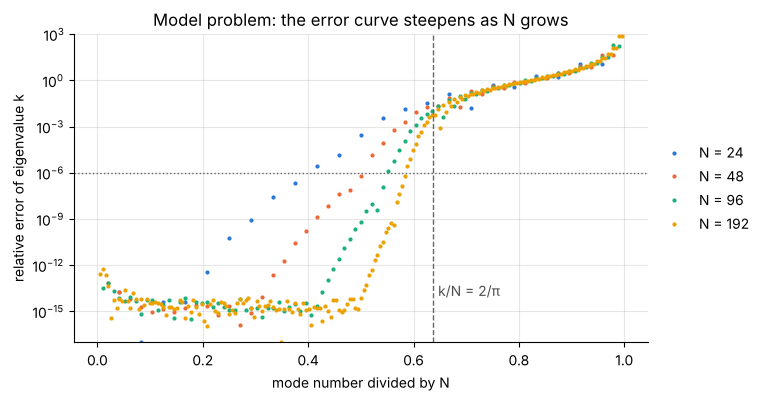

In [3]:
N_values = (24, 48, 96, 192)
counts, error_curves = [], {}
for N in N_values:
    computed = np.sort(np.linalg.eigvals(dirichlet_d2(N)[0]).real)[::-1]
    k = np.arange(1, N)
    exact = -(k * np.pi / 2) ** 2
    error_curves[N] = np.abs(computed - exact) / np.abs(exact)
    counts.append(int(np.argmax(error_curves[N] > 1e-6)))            # index of the first eigenvalue that fails
counts = np.array(counts)
fractions, gaps = counts / np.array(N_values), 2 * np.array(N_values) / np.pi - counts

print("   N   accurate to 1e-6   fraction of N    2N/π    2N/π − count")
for N, count, fraction, gap in zip(N_values, counts, fractions, gaps):
    print(f"{N:4d} {count:12d} {fraction:16.3f} {2 * N / np.pi:10.1f} {gap:11.1f}")
print(f"2/π = {2 / np.pi:.3f}")

fig, ax = plt.subplots(figsize=(7.4, 4))
for N in N_values:
    ax.semilogy(np.arange(1, N) / N, np.maximum(error_curves[N], 1e-17), ".", ms=4, label=f"N = {N}")
ax.axvline(2 / np.pi, color="0.4", ls="--", lw=1)
ax.axhline(1e-6, color="0.4", ls=":", lw=1)
ax.annotate("k/N = 2/π", xy=(2 / np.pi + 0.01, 1e-14), color="0.3")
ax.set(xlabel="mode number divided by N", ylabel="relative error of eigenvalue k", ylim=(1e-17, 1e3),
       title="Model problem: the error curve steepens as N grows")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [4]:
# verify: the counts respect the limit 2N/π, the fraction rises with N, and the shortfall becomes a smaller part of N
assert np.all(counts < 2 * np.array(N_values) / np.pi)
assert np.all(np.diff(fractions) > 0) and np.all(np.diff(gaps / np.array(N_values)) < 0)
assert all(error_curves[N][:N // 4].max() < 1e-9 for N in N_values)         # the lowest quarter is far better than 1e-6
assert 2 / np.pi - fractions[-1] < 0.06

**Answer.** The counts are 9, 24, 52 and 112, which are the fractions 0.375, 0.500, 0.542 and
0.583 of $N$. The fraction rises towards $2/\pi = 0.637$ and stays below it. The shortfall
$2N/\pi - \text{count}$ grows only from 6 to 10 while $N$ grows eightfold: the error curve
drops from order one to rounding level over a band of modes that becomes a smaller and
smaller part of the spectrum. So $2/\pi$ is the limit, but the approach is slow, and for the
values of $N$ used in practice "half of them" remains the honest working figure.

## Exercise 2

The anharmonic oscillator $-u'' + x^4 u = \lambda u$ on the real line has the ground-state
eigenvalue $\lambda_1 = 1.0603620905$. Reproduce it to nine digits by the truncation method
of 8.3, and report the values of $L$ and $N$ you needed and how you chose them. Also give
the next two eigenvalues to eight digits.

Cut the line off at $\pm L$ with $u(\pm L) = 0$ and scale the grid, as in 8.3; only the
potential changes. For large $|x|$ the eigenfunctions decay like $\exp(-|x|^3/3)$, faster than
those of the harmonic oscillator: that factor is $5\times10^{-10}$ at $x = 4$ and $10^{-18}$ at
$x = 5$, so a shorter domain than in 8.3 should do. Follow the procedure of 8.3: increase $L$
until the answer stops changing, then $N$, and check again.

In [5]:
def anharmonic_eigenvalues(N, L):
    """Eigenvalues of -u'' + x⁴ u on [-L, L] with u(±L) = 0, in increasing order."""
    D2, xi = dirichlet_d2(N)
    return np.sort(np.linalg.eigvals(-D2 / L**2 + np.diag((L * xi) ** 4)).real)

print("ground-state eigenvalue")
print("   L        N = 24          N = 36          N = 48          N = 64")
for L in (3, 4, 5, 6):
    print(f"{L:4d} " + "".join(f"{anharmonic_eigenvalues(N, L)[0]:16.10f}" for N in (24, 36, 48, 64)))

L_chosen, N_chosen = 5, 48
first_three = anharmonic_eigenvalues(N_chosen, L_chosen)[:3]
print(f"\nL = {L_chosen}, N = {N_chosen}:  λ = " + ", ".join(f"{value:.10f}" for value in first_three))

ground-state eigenvalue
   L        N = 24          N = 36          N = 48          N = 64
   3     1.0603621408    1.0603621400    1.0603621400    1.0603621400
   4     1.0603616633    1.0603620905    1.0603620905    1.0603620905
   5     1.0604474603    1.0603621251    1.0603620905    1.0603620905
   6     1.0574105880    1.0603585697    1.0603620889    1.0603620905

L = 5, N = 48:  λ = 1.0603620905, 3.7996730298, 7.4556979378


Read the table as in 8.3. With $L = 3$ the last column has converged in $N$ but to the wrong
number, 1.06036214: the wall squeezes the eigenfunction. From $L = 4$ on the converged value
no longer depends on $L$. A longer domain needs more points: $L = 6$ with $N = 36$ is in
error by $4\times10^{-6}$. $L = 5$ with $N = 48$ sits safely inside the region where neither parameter
matters.

The exercise supplies only $\lambda_1$, so the next two eigenvalues need a check of their own.
A different method serves: the Fourier matrix of notebook 2 on a periodic interval of length
$2L$. It shares nothing with the Chebyshev computation except the truncation idea, and periodic
boundary conditions are as good as $u(\pm L) = 0$ for a function that is $10^{-18}$ there.

In [6]:
# verify: the given value of λ_1, a larger domain with a finer grid, and an independent Fourier discretization
assert abs(first_three[0] - 1.0603620905) < 5e-10
assert np.abs(anharmonic_eigenvalues(80, 6)[:3] - first_three).max() < 5e-9

M = 64                                                                # periodic grid on [-L, L): x = L (θ - π)/π
x_periodic = -L_chosen + 2 * L_chosen * np.arange(M) / M
H_fourier = -(np.pi / L_chosen) ** 2 * fourier_diff2_matrix(M) + np.diag(x_periodic**4)
fourier_three = np.linalg.eigvalsh(H_fourier)[:3]
print("Fourier method, 64 points:  λ = " + ", ".join(f"{value:.10f}" for value in fourier_three))
assert np.abs(fourier_three - first_three).max() < 5e-9

Fourier method, 64 points:  λ = 1.0603620905, 3.7996730298, 7.4556979380


**Answer.** $L = 5$ and $N = 48$ give $\lambda_1 = 1.0603620905$, all ten digits of the value
quoted. The next two eigenvalues are $\lambda_2 = 3.79967303$ and $\lambda_3 = 7.45569794$,
confirmed to eight digits by a larger domain with a finer grid and by a Fourier
discretization. The levels of the quartic well move apart as the energy rises (gaps 2.74 and
3.66), where those of the harmonic oscillator are equally spaced: the walls of the well are
steeper.

## Exercise 3

Longitudinal vibrations of a bar whose cross-section area grows as $A(x) = (1+x)^2$ on
$0 \le x \le 1$, fixed at both ends, satisfy $(A\,u')' + \mu\,A\,u = 0$ with
$u(0) = u(1) = 0$. Solve it as a generalized eigenvalue problem with $N = 24$ and give the
first four values of $\sqrt{\mu}$. Compare them with those of a uniform bar,
$\sqrt{\mu} = k\pi$, and explain the result with the substitution $v = (1+x)\,u$.

Map the grid to $[0, 1]$ with $x = (\xi + 1)/2$, which multiplies $D$ by 2. On the grid
$(A u')'$ is $D\,\mathrm{diag}(A)\,D$, and the problem reads
$-D\,\mathrm{diag}(A)\,D\,\mathbf{u} = \mu\,B\,\mathbf{u}$ with $B = \mathrm{diag}(A)$. Both
ends are fixed, so the rows for index 0 ($x = 1$) and index $N$ ($x = 0$) are replaced by
$u = 0$ and the same rows of $B$ are set to zero. That gives two infinite eigenvalues, which
are discarded as in 8.2.

In [7]:
area = lambda x: (1 + x) ** 2

def bar_modes(N):
    """√μ and mode shapes of the tapered bar; index 0 is the end x = 1 and index N the end x = 0."""
    D, xi = cheb(N)
    D, x = 2 * D, (xi + 1) / 2                             # map [-1, 1] to [0, 1]
    stiffness = -D @ np.diag(area(x)) @ D                  # -(A u')'
    B = np.diag(area(x))
    for row in (0, N):                                     # both ends fixed: u = 0, no eigenvalue in these rows
        stiffness[row, :], stiffness[row, row], B[row, row] = 0.0, 1.0, 0.0
    values, vectors = eig(stiffness, B)
    keep = np.isfinite(values) & (np.abs(values.imag) < 1e-8) & (values.real > 0)
    order = np.argsort(values.real[keep])
    return np.sqrt(values.real[keep][order]), vectors.real[:, keep][:, order], x

root_mu, shapes, x = bar_modes(24)
print("mode    √μ (tapered bar)       kπ (uniform bar)      difference")
for i in range(4):
    print(f"{i + 1:3d} {root_mu[i]:20.12f} {(i + 1) * np.pi:20.12f} {abs(root_mu[i] - (i + 1) * np.pi):14.1e}")

mode    √μ (tapered bar)       kπ (uniform bar)      difference
  1       3.141592653590       3.141592653590        3.0e-14
  2       6.283185307180       6.283185307180        1.2e-14
  3       9.424777960769       9.424777960769        8.9e-15
  4      12.566370614359      12.566370614359        2.5e-14


The frequencies are those of the uniform bar. The substitution shows why. With
$u = v/(1+x)$,

$$A\,u' = (1+x)\,v' - v,\qquad (A\,u')' = (1+x)\,v'' + v' - v' = (1+x)\,v'' ,$$

and $\mu A u = \mu\,(1+x)\,v$. Dividing by $1 + x$ leaves $v'' + \mu v = 0$ with
$v(0) = v(1) = 0$: the equation of the uniform bar. So $\sqrt\mu = k\pi$ exactly, and the mode
shapes are $u_k = \sin(k\pi x)/(1+x)$. This is derived by hand, independently of the matrices,
and serves as the check.

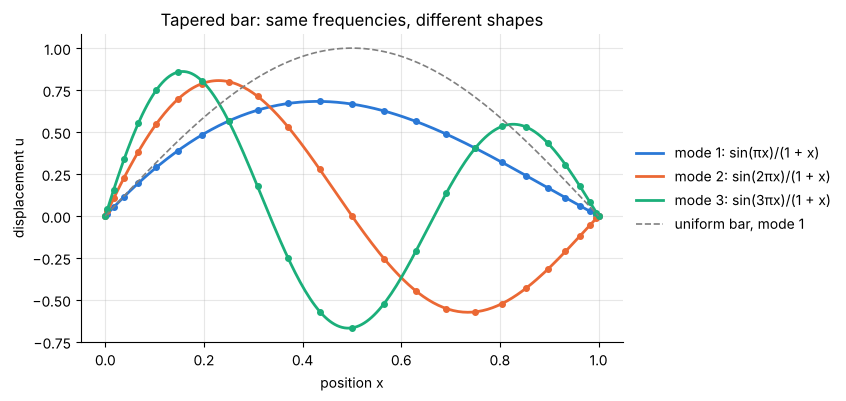

In [8]:
# verify: against √μ = kπ, against the mode shapes sin(kπx)/(1 + x), and with the two-grid test
assert np.abs(root_mu[:4] - np.pi * np.arange(1, 5)).max() < 1e-10
assert np.abs(bar_modes(32)[0][:4] - root_mu[:4]).max() < 1e-10

fine = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(7, 4))
for i in range(3):
    exact_shape = np.sin((i + 1) * np.pi * x) / (1 + x)
    peak = np.abs(exact_shape).argmax()
    shape = shapes[:, i] * exact_shape[peak] / shapes[peak, i]              # an eigenvector has no scale of its own
    assert np.abs(shape - exact_shape).max() < 1e-10
    line, = ax.plot(fine, np.sin((i + 1) * np.pi * fine) / (1 + fine), label=f"mode {i + 1}: sin({i + 1 if i else ''}πx)/(1 + x)")
    ax.plot(x, shape, "o", ms=4, color=line.get_color())
ax.plot(fine, np.sin(np.pi * fine), "--", color="0.5", lw=1.2, label="uniform bar, mode 1")
ax.set(xlabel="position x", ylabel="displacement u", title="Tapered bar: same frequencies, different shapes")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

**Answer.** $\sqrt\mu = 3.14159265, 6.28318531, 9.42477796, 12.56637061$: the values $k\pi$ of
the uniform bar, reproduced to better than $10^{-10}$ with $N = 24$. The taper changes the
shapes, $u_k = \sin(k\pi x)/(1+x)$ (dots: computed, lines: exact), with larger motion at the
thin end, but not the frequencies. An area that grows as the square of the distance is a cone,
and $v = (1+x)u$ is the substitution that turns a spherical wave into a plane one. The same
mathematics describes sound in a conical horn.

## Exercise 4

A rectangular membrane occupies $-1 \le x \le 1$, $-\tfrac12 \le y \le \tfrac12$ and is fixed
at the edge. Scale the $y$ derivative, build the Kronecker sum with $N = 20$ in each
direction and compute the ten lowest eigenvalues. Compare with the exact values
$-\tfrac{\pi^2}{4}(m^2 + 4n^2)$. Which is the lowest degenerate pair, and why are there fewer
of them than for the square?

With $y = \eta/2$ and $\eta$ on the Chebyshev grid, $\partial/\partial y = 2\,\partial/\partial\eta$,
so the second-derivative matrix in $y$ is $4D^2$. The Kronecker sum is then
$I \otimes D^2 + 4D^2 \otimes I$. The exact modes are
$\sin\tfrac{m\pi(x+1)}{2}\,\sin n\pi(y + \tfrac12)$, with $-\lambda = (m\pi/2)^2 + (n\pi)^2$.

In [9]:
N = 20
D2, xi = dirichlet_d2(N)
I = np.eye(N - 1)
laplacian = np.kron(I, D2) + np.kron(4 * D2, I)                     # x derivative unchanged, y derivative scaled by 2² = 4
values = np.sort(np.linalg.eigvals(laplacian).real)[::-1]           # from the smallest |λ| upwards

pairs = sorted((m * m + 4 * n * n, m, n) for m in range(1, 12) for n in range(1, 8))[:10]
print("computed -λ/(π²/4)    exact m² + 4n²   (m, n)")
for value, (total, m, n) in zip(values[:10], pairs):
    print(f"{-value / (np.pi**2 / 4):16.10f} {total:12d}         ({m}, {n})")

def repeated(weight, count=30):
    """Number of repeated values among the lowest `count` values of m² + weight n²."""
    lowest = sorted(m * m + weight * n * n for m in range(1, 40) for n in range(1, 40))[:count]
    return count - len(set(lowest))
print(f"\namong the 30 lowest modes, eigenvalues that repeat an earlier one:  square {repeated(1)},  rectangle {repeated(4)}")

computed -λ/(π²/4)    exact m² + 4n²   (m, n)
    5.0000000000            5         (1, 1)
    8.0000000000            8         (2, 1)
   13.0000000000           13         (3, 1)
   17.0000000000           17         (1, 2)
   19.9999999997           20         (2, 2)
   20.0000000000           20         (4, 1)
   25.0000000000           25         (3, 2)
   28.9999999852           29         (5, 1)
   31.9999999997           32         (4, 2)
   37.0000000000           37         (1, 3)

among the 30 lowest modes, eigenvalues that repeat an earlier one:  square 13,  rectangle 7


In [10]:
# verify: against the exact eigenvalues, the degenerate pair, and a finer grid
assert np.abs(-values[:10] / (np.pi**2 / 4) - [p[0] for p in pairs]).max() < 1e-6
assert abs(values[4] - values[5]) < 1e-8 and pairs[4][0] == pairs[5][0] == 20
assert min(abs(values[i] - values[i + 1]) for i in (0, 1, 2, 3, 5, 6, 7, 8)) > 1.0      # no other pair among the ten
D2_fine, _ = dirichlet_d2(26)
fine_values = np.sort(np.linalg.eigvals(np.kron(np.eye(25), D2_fine) + np.kron(4 * D2_fine, np.eye(25))).real)[::-1]
assert np.abs(fine_values[:10] - values[:10]).max() < 1e-6

**Answer.** The ten lowest values of $-4\lambda/\pi^2$ are 5, 8, 13, 17, 20, 20, 25, 29, 32 and
37, reproduced to within $2\times10^{-8}$ with $N = 20$ (the eighth, with five half-waves
along $x$, is the least accurate). The lowest degenerate pair is the fifth and sixth:
$(m, n) = (2, 2)$ and $(4, 1)$, both with $m^2 + 4n^2 = 20$.

The square has a symmetry, the exchange of $x$ and $y$, that turns mode $(m, n)$ into
$(n, m)$, so every mode with $m \ne n$ has a partner. The rectangle has lost that symmetry
and its degeneracies need a coincidence, $m^2 + 4n^2 = m'^2 + 4n'^2$. For a rectangle with an
irrational ratio of the squared sides there would be none at all. Here the ratio of the sides
is 2, and a remnant survives: a mode with even $m = 2p$ has a nodal line at $x = 0$, so it is
also a mode of each unit square half, where $(p, n)$ and $(n, p)$ are partners. That gives
the pairs $(2p, n)$ and $(2n, p)$, of which $(2, 2)$ and $(4, 1)$ is the first. Modes with odd
$m$ have no partner of this kind. Among the 30 lowest modes the square has 13 repeated
eigenvalues and the rectangle 7.

## Exercise 5

For the convection-diffusion operator of 8.5 with $N = 60$, compute $\|e^{t\mathcal{L}}\|$
in the weighted norm of 8.6 for $\nu = 0.05$, $0.02$ and $0.01$, and find for each the time
at which it first falls below $10^{-3}$. Compare with the estimate $\ln(1000)/|\lambda_1|$
from the first eigenvalue. Which simple physical time scale do your results follow instead?

The norm is the 2-norm of the matrix exponential of $W^{1/2}AW^{-1/2}$, as in 8.6. It never
increases (8.6 showed why), so the level $10^{-3}$ is crossed once and a root finder locates
the crossing. If eigenvalues told the story, the norm would be $e^{\lambda_1t}$ and the crossing
would come at $\ln(1000)/|\lambda_1|$ with $\lambda_1 = -1/(4\nu) - \nu\pi^2/4$.

    ν       λ_1     ln(1000)/|λ_1|   time to reach 1e-3    ratio    ‖exp(tL)‖ at t = 1
  0.05    -5.123         1.348             3.490          2.6          0.778
  0.02   -12.549         0.550             2.908          5.3          0.886
  0.01   -25.025         0.276             2.626          9.5          0.934


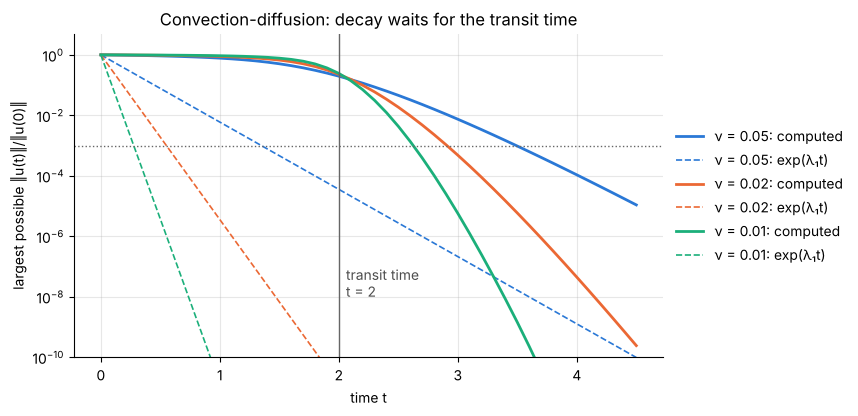

In [11]:
def decay(N, nu):
    """The function t ↦ ‖exp(t L)‖ in the weighted norm, and the time at which it falls to 1e-3."""
    A_weighted = weighted(convection_diffusion(N, nu)[0], N)
    size = lambda t: np.linalg.norm(expm(t * A_weighted), 2)
    return size, brentq(lambda t: size(t) - 1e-3, 1.0, 6.0, xtol=1e-9)

times = np.linspace(0, 4.5, 46)
results = {}
print("    ν       λ_1     ln(1000)/|λ_1|   time to reach 1e-3    ratio    ‖exp(tL)‖ at t = 1")
fig, ax = plt.subplots(figsize=(7.6, 4.2))
for nu in (0.05, 0.02, 0.01):
    size, t_cross = decay(60, nu)
    lam_1 = exact_cd_eigenvalues(nu, 1)[0]
    t_eigenvalue = np.log(1000) / abs(lam_1)
    curve = np.array([size(t) for t in times])
    results[nu] = (t_cross, t_eigenvalue, curve)
    print(f"{nu:6.2f} {lam_1:9.3f} {t_eigenvalue:13.3f} {t_cross:17.3f} {t_cross / t_eigenvalue:12.1f} {size(1.0):14.3f}")
    line, = ax.semilogy(times, curve, label=f"ν = {nu}: computed")
    ax.semilogy(times, np.exp(lam_1 * times), "--", lw=1.2, color=line.get_color(), label=f"ν = {nu}: exp(λ₁t)")
ax.axhline(1e-3, color="0.4", ls=":", lw=1)
ax.axvline(2, color="0.4", lw=1)
ax.annotate("transit time\nt = 2", xy=(2.06, 1e-8), color="0.3")
ax.set(xlabel="time t", ylabel="largest possible ‖u(t)‖/‖u(0)‖", ylim=(1e-10, 5),
       title="Convection-diffusion: decay waits for the transit time")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [12]:
# verify: a finer grid gives the same times; the norm never grows; the times exceed the transit time and approach it
for nu, (t_cross, t_eigenvalue, curve) in results.items():
    assert abs(decay(90, nu)[1] - t_cross) < 1e-5
    assert np.all(np.diff(curve) < 0) and curve[10] > 0.75               # almost nothing is lost up to t = 1
    assert t_cross > 2.0 and t_cross > 2.5 * t_eigenvalue
crossing = np.array([results[nu][0] for nu in (0.05, 0.02, 0.01)])
assert np.all(np.diff(crossing) < 0)                                     # closer to 2 as ν decreases
excess_ratio = (crossing[0] - 2) / (crossing[2] - 2)
print(f"excess over the transit time: {crossing[0] - 2:.2f}, {crossing[1] - 2:.2f}, {crossing[2] - 2:.2f};  ratio first/last {excess_ratio:.2f}  (√5 = {np.sqrt(5):.2f})")
assert abs(excess_ratio / np.sqrt(5) - 1) < 0.15

excess over the transit time: 1.49, 0.91, 0.63;  ratio first/last 2.38  (√5 = 2.24)


**Answer.** The norm falls below $10^{-3}$ at $t = 3.49$, $2.91$ and $2.63$ for
$\nu = 0.05$, $0.02$ and $0.01$. The eigenvalue estimates are $1.35$, $0.55$ and $0.28$: too
short by factors of 2.6, 5.3 and 9.5, and wrong in trend as well as in size, since they are
proportional to $\nu$ while the true times hardly change.

The times follow the **transit time**: the length of the channel divided by the speed of the
flow, $2/1 = 2$. A disturbance released near the right wall is carried the whole way to the
left wall before it can be destroyed there, and until then it loses little (at $t = 1$ the
norm is still 0.78, 0.89 and 0.93). The excess over 2 is the effect of diffusion, which spreads
the pulse so that its tail arrives late; it shrinks roughly as $\sqrt\nu$ (1.49, 0.91, 0.63).
To estimate how long it takes to flush a channel, divide its length by the flow speed. The
leading eigenvalue describes only what is left after that.